In [2]:
# Step 1: Import Required Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [3]:
# Step 2: Generate Student Academic Performance Dataset

# Set random seed for reproducibility
np.random.seed(42)

# Dataset configuration
n_students = 100

subjects = [
    "Mathematics",
    "Physics",
    "Chemistry",
    "Biology",
    "English"
]

# Generate overall student academic ability
student_ability = np.random.normal(70, 10, n_students)

# Subject-specific variations
subject_offsets = [-2, 1, 0, -1, 2]
subject_noise = [9, 10, 11, 12, 9]

# Generate subject scores
scores = {}

for i, subject in enumerate(subjects):

    subject_scores = (
        student_ability
        + subject_offsets[i]
        + np.random.normal(0, subject_noise[i], n_students)
    )

    scores[subject] = np.clip(
        np.round(subject_scores),
        0,
        100
    ).astype(int)

# Create DataFrame
df = pd.DataFrame(scores)

# Add Student IDs
df.insert(
    0,
    "Student_ID",
    [f"STU{str(i).zfill(3)}" for i in range(1, n_students + 1)]
)

print("Dataset Generated Successfully!")

df.head(10)

Dataset Generated Successfully!


,Student_ID,Mathematics,Physics,Chemistry,Biology,English
0,STU001,60,80,66,55,85
1,STU002,63,75,62,60,88
2,STU003,71,88,85,76,66
3,STU004,76,97,92,85,92
4,STU005,64,55,67,61,64
5,STU006,69,59,69,74,65
6,STU007,100,92,100,72,82
7,STU008,77,84,71,75,72
8,STU009,66,71,71,66,68
9,STU010,73,100,73,81,70


In [4]:
# Step 3: Save Dataset

df.to_csv("student_performance_dataset.csv", index=False)

df.to_excel("student_performance_dataset.xlsx", index=False)

print("CSV and Excel files saved successfully!")

CSV and Excel files saved successfully!


In [5]:
# Step 4: Dataset Information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (100, 6)

Column Names:
['Student_ID', 'Mathematics', 'Physics', 'Chemistry', 'Biology', 'English']

Missing Values:
Student_ID     0
Mathematics    0
Physics        0
Chemistry      0
Biology        0
English        0
dtype: int64

Statistical Summary:


,Mathematics,Physics,Chemistry,Biology,English
count,100.000000,100.000000,100.000000,100.000000,100.00000
mean,67.170000,70.370000,70.110000,67.160000,69.95000
std,11.553175,14.811717,12.172908,14.201095,11.22351
min,41.000000,28.000000,41.000000,33.000000,35.00000
25%,59.750000,58.750000,62.000000,58.750000,64.00000
50%,67.000000,72.000000,69.500000,66.500000,70.00000
75%,73.000000,80.000000,79.000000,76.000000,76.00000
max,100.000000,100.000000,100.000000,100.000000,100.00000


In [6]:
# Part A: Vector & Matrix Fundamentals

# Extract subject scores
score_matrix = df[subjects].to_numpy(dtype=float)

# Display first student's vector
student_1 = score_matrix[0]

print("Student 1 Score Vector:")
print(student_1)

print("\nNumber of Dimensions:", len(student_1))

# Display first five students
print("\nFirst Five Students' Vectors:")

for i in range(5):
    print(f"Student {i+1}: {score_matrix[i]}")

Student 1 Score Vector:
[60. 80. 66. 55. 85.]

Number of Dimensions: 5

First Five Students' Vectors:
Student 1: [60. 80. 66. 55. 85.]
Student 2: [63. 75. 62. 60. 88.]
Student 3: [71. 88. 85. 76. 66.]
Student 4: [76. 97. 92. 85. 92.]
Student 5: [64. 55. 67. 61. 64.]


In [7]:
# Calculate Norm-1 and Norm-2

# Select first student's vector
vector = student_1

# Norm-1
norm_1 = np.linalg.norm(vector, ord=1)

# Norm-2
norm_2 = np.linalg.norm(vector, ord=2)

print("Student 1 Vector:", vector)

print("\nNorm-1:", round(norm_1, 2))

print("Norm-2:", round(norm_2, 2))

Student 1 Vector: [60. 80. 66. 55. 85.]

Norm-1: 346.0
Norm-2: 156.86


In [8]:
# Calculate Norms for Every Student

norm_results = pd.DataFrame({
    "Student_ID": df["Student_ID"],
    "Norm_1": np.linalg.norm(score_matrix, ord=1, axis=1),
    "Norm_2": np.linalg.norm(score_matrix, ord=2, axis=1)
})

display(norm_results.head(10))

,Student_ID,Norm_1,Norm_2
0,STU001,346.0,156.862998
1,STU002,348.0,157.422997
2,STU003,386.0,173.614516
3,STU004,442.0,198.338095
4,STU005,311.0,139.380773
5,STU006,336.0,150.678466
6,STU007,446.0,200.927848
7,STU008,379.0,169.808716
8,STU009,342.0,153.029409
9,STU010,397.0,179.217745


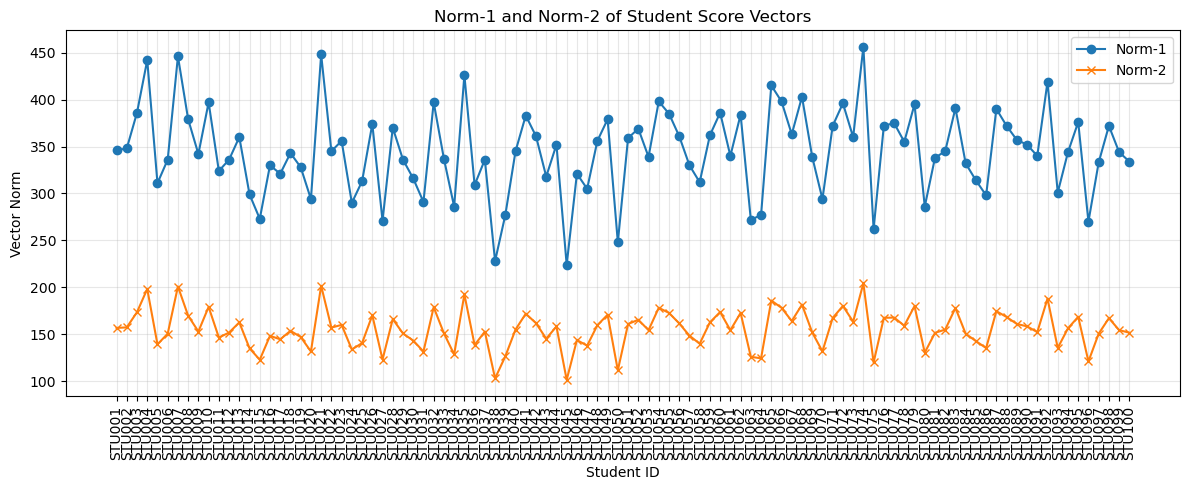

In [9]:
# Visualize Norm-1 and Norm-2

plt.figure(figsize=(12, 5))

plt.plot(
    norm_results["Student_ID"],
    norm_results["Norm_1"],
    label="Norm-1",
    marker="o"
)

plt.plot(
    norm_results["Student_ID"],
    norm_results["Norm_2"],
    label="Norm-2",
    marker="x"
)

plt.title("Norm-1 and Norm-2 of Student Score Vectors")
plt.xlabel("Student ID")
plt.ylabel("Vector Norm")
plt.xticks(rotation=90)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# Dot Product Between Two Students

# Select two students
vector_A = score_matrix[0]
vector_B = score_matrix[1]

# Calculate Dot Product
dot_product = np.dot(vector_A, vector_B)

print("Student 1 Vector:", vector_A)
print("Student 2 Vector:", vector_B)

print("\nDot Product:", dot_product)

Student 1 Vector: [60. 80. 66. 55. 85.]
Student 2 Vector: [63. 75. 62. 60. 88.]

Dot Product: 24652.0


In [11]:
# Calculate Angle Between Two Students

# Calculate vector magnitudes
magnitude_A = np.linalg.norm(vector_A)
magnitude_B = np.linalg.norm(vector_B)

# Calculate cosine similarity
cos_theta = dot_product / (magnitude_A * magnitude_B)

# Avoid floating-point errors
cos_theta = np.clip(cos_theta, -1, 1)

# Calculate angle in degrees
angle_radians = np.arccos(cos_theta)
angle_degrees = np.degrees(angle_radians)

print("Dot Product:", dot_product)
print("Cosine Value:", round(cos_theta, 4))
print("Angle (Radians):", round(angle_radians, 4))
print("Angle (Degrees):", round(angle_degrees, 2))

Dot Product: 24652.0
Cosine Value: 0.9983
Angle (Radians): 0.0582
Angle (Degrees): 3.34


### Dot Product and Angle – Interpretation

The dot product was calculated between the score vectors of Student 1 and Student 2.

The angle between the vectors was determined using the inverse cosine formula.

A smaller angle indicates that the two students have more similar relative subject-score patterns, whereas a larger angle indicates greater differences in their score patterns.

This analysis demonstrates the application of vector geometry to student academic performance data.

In [12]:
# Cross Product of Two Students (3D)

# Select first three subjects
vector_A_3D = score_matrix[0, :3]
vector_B_3D = score_matrix[1, :3]

# Calculate Cross Product
cross_product = np.cross(vector_A_3D, vector_B_3D)

print("Student 1 - 3D Vector:", vector_A_3D)
print("Student 2 - 3D Vector:", vector_B_3D)

print("\nCross Product:")
print(cross_product)

# Calculate magnitude
cross_magnitude = np.linalg.norm(cross_product)

print("\nCross Product Magnitude:", round(cross_magnitude, 2))

Student 1 - 3D Vector: [60. 80. 66.]
Student 2 - 3D Vector: [63. 75. 62.]

Cross Product:
[  10.  438. -540.]

Cross Product Magnitude: 695.37


In [13]:
# Verify Perpendicular Property

dot_A = np.dot(cross_product, vector_A_3D)
dot_B = np.dot(cross_product, vector_B_3D)

print("Dot Product with Student 1:", dot_A)
print("Dot Product with Student 2:", dot_B)

if np.isclose(dot_A, 0) and np.isclose(dot_B, 0):
    print("\nVerification Successful!")
    print("Cross Product is perpendicular to both vectors.")
else:
    print("\nVerification Failed!")

Dot Product with Student 1: 0.0
Dot Product with Student 2: 0.0

Verification Successful!
Cross Product is perpendicular to both vectors.


### Cross Product – Interpretation

The cross product was calculated between the first three subject-score vectors of Student 1 and Student 2.

Mathematics, Physics and Chemistry were selected to construct three-dimensional vectors.

The resulting cross product is perpendicular to both original vectors. Its magnitude represents the area of the parallelogram formed by the two vectors.

This demonstrates the application of three-dimensional vector operations to academic performance data.

In [14]:
# Vector Projection

# Select two student vectors
vector_A = score_matrix[0]
vector_B = score_matrix[1]

# Calculate dot product
dot_product = np.dot(vector_A, vector_B)

# Calculate projection of A onto B
projection = (
    dot_product / np.dot(vector_B, vector_B)
) * vector_B

print("Student 1 Vector:", vector_A)
print("Student 2 Vector:", vector_B)

print("\nProjection of Student 1 onto Student 2:")
print(np.round(projection, 2))

print("\nProjection Magnitude:")
print(round(np.linalg.norm(projection), 2))

Student 1 Vector: [60. 80. 66. 55. 85.]
Student 2 Vector: [63. 75. 62. 60. 88.]

Projection of Student 1 onto Student 2:
[62.67 74.61 61.67 59.69 87.54]

Projection Magnitude:
156.6


In [15]:
#  Verify Vector Projection

# Calculate perpendicular component
perpendicular_component = vector_A - projection

# Verify reconstruction
reconstructed_vector = projection + perpendicular_component

print("Projection Vector:")
print(np.round(projection, 2))

print("\nPerpendicular Component:")
print(np.round(perpendicular_component, 2))

print("\nReconstructed Vector:")
print(np.round(reconstructed_vector, 2))

if np.allclose(vector_A, reconstructed_vector):
    print("\nVerification Successful!")
    print("Original vector reconstructed correctly.")
else:
    print("\nVerification Failed!")

Projection Vector:
[62.67 74.61 61.67 59.69 87.54]

Perpendicular Component:
[-2.67  5.39  4.33 -4.69 -2.54]

Reconstructed Vector:
[60. 80. 66. 55. 85.]

Verification Successful!
Original vector reconstructed correctly.


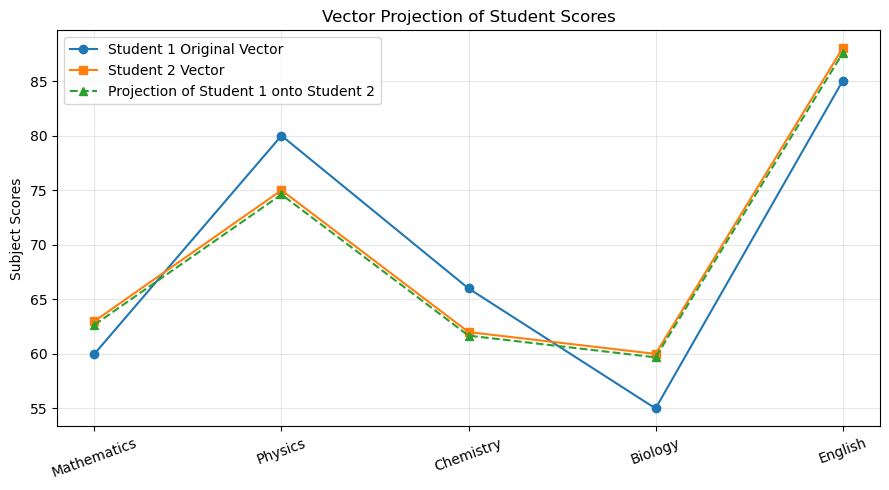

In [16]:
# Step 21: Visualize Vector Projection

plt.figure(figsize=(9, 5))

x = np.arange(len(subjects))

plt.plot(
    x, vector_A,
    marker="o",
    label="Student 1 Original Vector"
)

plt.plot(
    x, vector_B,
    marker="s",
    label="Student 2 Vector"
)

plt.plot(
    x, projection,
    marker="^",
    linestyle="--",
    label="Projection of Student 1 onto Student 2"
)

plt.xticks(x, subjects, rotation=20)
plt.ylabel("Subject Scores")
plt.title("Vector Projection of Student Scores")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Vector Projection – Interpretation

The projection of Student 1's score vector onto Student 2's score vector was calculated using the dot product formula.

The projected vector represents the component of Student 1's academic performance along the direction of Student 2's performance vector.

The remaining perpendicular component represents the difference that cannot be explained by the projection.

This demonstrates the practical application of vector projection in comparing multidimensional academic performance data.

In [17]:
#  Create Two Matrices

# Matrix A: First 5 students
matrix_A = score_matrix[0:5, :]

# Matrix B: Next 5 students
matrix_B = score_matrix[5:10, :]

print("Matrix A:")
print(matrix_A)

print("\nMatrix B:")
print(matrix_B)

print("\nShape of Matrix A:", matrix_A.shape)
print("Shape of Matrix B:", matrix_B.shape)

Matrix A:
[[60. 80. 66. 55. 85.]
 [63. 75. 62. 60. 88.]
 [71. 88. 85. 76. 66.]
 [76. 97. 92. 85. 92.]
 [64. 55. 67. 61. 64.]]

Matrix B:
[[ 69.  59.  69.  74.  65.]
 [100.  92. 100.  72.  82.]
 [ 77.  84.  71.  75.  72.]
 [ 66.  71.  71.  66.  68.]
 [ 73. 100.  73.  81.  70.]]

Shape of Matrix A: (5, 5)
Shape of Matrix B: (5, 5)


In [18]:
# Matrix Addition

matrix_addition = matrix_A + matrix_B

print("Matrix Addition (A + B):")
print(matrix_addition)

Matrix Addition (A + B):
[[129. 139. 135. 129. 150.]
 [163. 167. 162. 132. 170.]
 [148. 172. 156. 151. 138.]
 [142. 168. 163. 151. 160.]
 [137. 155. 140. 142. 134.]]


In [19]:
# Matrix Multiplication

matrix_multiplication = np.dot(matrix_A, matrix_B.T)

print("Matrix Multiplication (A x B Transpose):")
print(matrix_multiplication)

print("\nResult Shape:", matrix_multiplication.shape)

Matrix Multiplication (A x B Transpose):
[[23009. 30890. 26271. 23736. 27603.]
 [23210. 30936. 26389. 23829. 27645.]
 [25870. 34580. 29346. 26473. 30964.]
 [29585. 39388. 33531. 30301. 35289.]
 [20958. 27800. 23488. 21264. 24484.]]

Result Shape: (5, 5)


In [20]:
# Matrix Transpose

matrix_transpose = matrix_A.T

print("Original Matrix A:")
print(matrix_A)

print("\nTranspose of Matrix A:")
print(matrix_transpose)

print("\nOriginal Shape:", matrix_A.shape)
print("Transpose Shape:", matrix_transpose.shape)

Original Matrix A:
[[60. 80. 66. 55. 85.]
 [63. 75. 62. 60. 88.]
 [71. 88. 85. 76. 66.]
 [76. 97. 92. 85. 92.]
 [64. 55. 67. 61. 64.]]

Transpose of Matrix A:
[[60. 63. 71. 76. 64.]
 [80. 75. 88. 97. 55.]
 [66. 62. 85. 92. 67.]
 [55. 60. 76. 85. 61.]
 [85. 88. 66. 92. 64.]]

Original Shape: (5, 5)
Transpose Shape: (5, 5)


In [21]:
#  Calculate Determinant

determinant = np.linalg.det(matrix_A)

print("Determinant of Matrix A:")
print(round(determinant, 4))

if not np.isclose(determinant, 0):
    print("\nMatrix is Non-Singular.")
else:
    print("\nMatrix is Singular.")

Determinant of Matrix A:
-3717169.0

Matrix is Non-Singular.


In [23]:
#  Calculate Matrix Inverse

if not np.isclose(determinant, 0):

    matrix_inverse = np.linalg.inv(matrix_A)

    print("Inverse of Matrix A:")
    print(np.round(matrix_inverse, 4))

    # Verify inverse
    identity_matrix = np.dot(matrix_A, matrix_inverse)

    print("\nVerification (A x A_inverse):")
    print(np.round(identity_matrix, 4))

else:
    print("Matrix Inverse does not exist.")

Inverse of Matrix A:
[[-0.0072  0.0637  0.0757 -0.1271  0.0266]
 [ 0.      0.0327  0.0525 -0.0347 -0.0492]
 [ 0.1032 -0.1505 -0.058   0.0558  0.0494]
 [-0.1227  0.0806 -0.0075  0.0635 -0.0313]
 [ 0.0161 -0.0109 -0.053   0.0379  0.0095]]

Verification (A x A_inverse):
[[ 1. -0. -0.  0. -0.]
 [-0.  1.  0. -0. -0.]
 [-0. -0.  1.  0.  0.]
 [ 0. -0. -0.  1. -0.]
 [ 0. -0. -0. -0.  1.]]


### Matrix Operations – Interpretation

Matrix operations were performed using two selected groups of student academic performance scores.

Matrix addition was used to demonstrate element-wise addition of corresponding matrix elements.

Matrix multiplication was performed using Matrix A and the transpose of Matrix B.

The transpose operation interchanged rows and columns.

The determinant was calculated to examine whether the selected square matrix was singular or non-singular.

The inverse was calculated only when the determinant was non-zero.

These operations demonstrate the fundamental applications of matrices in linear algebra and data analysis.

# Part B – Matrix Operations

This section focuses on performing matrix operations on student academic performance data, including matrix addition, multiplication, transpose, inverse and determinant.

In [24]:
# Check dataset dimensions

print("Total Students:", score_matrix.shape[0])
print("Total Subjects:", score_matrix.shape[1])

print("\nDataset Dimensions:", score_matrix.shape)

print("\nDimensionality:")
print("1D: Line")
print("2D: Plane")
print("3D: Three-dimensional space")
print("5D: Five-dimensional feature space")

print("\nHyperplane in 5D space has dimension:", score_matrix.shape[1] - 1)

Total Students: 100
Total Subjects: 5

Dataset Dimensions: (100, 5)

Dimensionality:
1D: Line
2D: Plane
3D: Three-dimensional space
5D: Five-dimensional feature space

Hyperplane in 5D space has dimension: 4


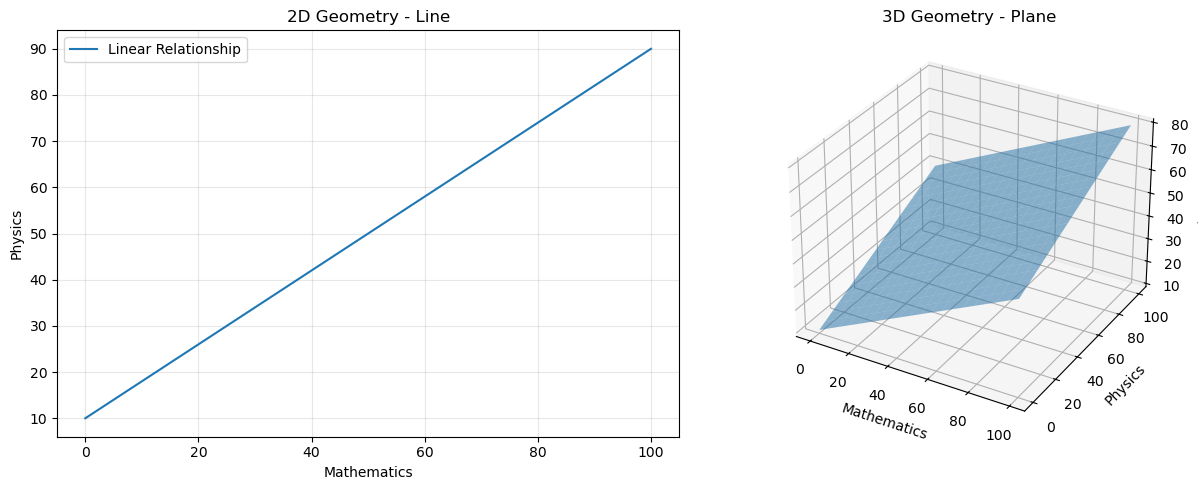

In [25]:
# Import visualization libraries

import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure(figsize=(13, 5))

# 2D Line
ax1 = fig.add_subplot(121)

x = np.linspace(0, 100, 100)
y = 0.8 * x + 10

ax1.plot(x, y, label="Linear Relationship")
ax1.set_title("2D Geometry - Line")
ax1.set_xlabel("Mathematics")
ax1.set_ylabel("Physics")
ax1.legend()
ax1.grid(alpha=0.3)

# 3D Plane
ax2 = fig.add_subplot(122, projection='3d')

x = np.linspace(0, 100, 20)
y = np.linspace(0, 100, 20)

X, Y = np.meshgrid(x, y)
Z = 0.4 * X + 0.3 * Y + 10

ax2.plot_surface(X, Y, Z, alpha=0.5)

ax2.set_title("3D Geometry - Plane")
ax2.set_xlabel("Mathematics")
ax2.set_ylabel("Physics")
ax2.set_zlabel("Chemistry")

plt.tight_layout()
plt.show()

### Line, Plane and Hyperplane – Interpretation

The student performance dataset contains five subject features: Mathematics, Physics, Chemistry, Biology and English.

A line represents one-dimensional geometry, while a plane represents two-dimensional geometry.

Three-dimensional space represents data using three independent coordinate axes.

A hyperplane is a generalization of a plane in higher-dimensional space. In a five-dimensional feature space, a hyperplane has four dimensions.

These geometric concepts help explain how multidimensional student performance data can be represented and analyzed using linear algebra.

# Part C – Linear Transformations & Geometry

This section explores geometric representations of student performance data through lines, planes and hyperplanes, demonstrating dimensionality from 2D to higher-dimensional spaces.

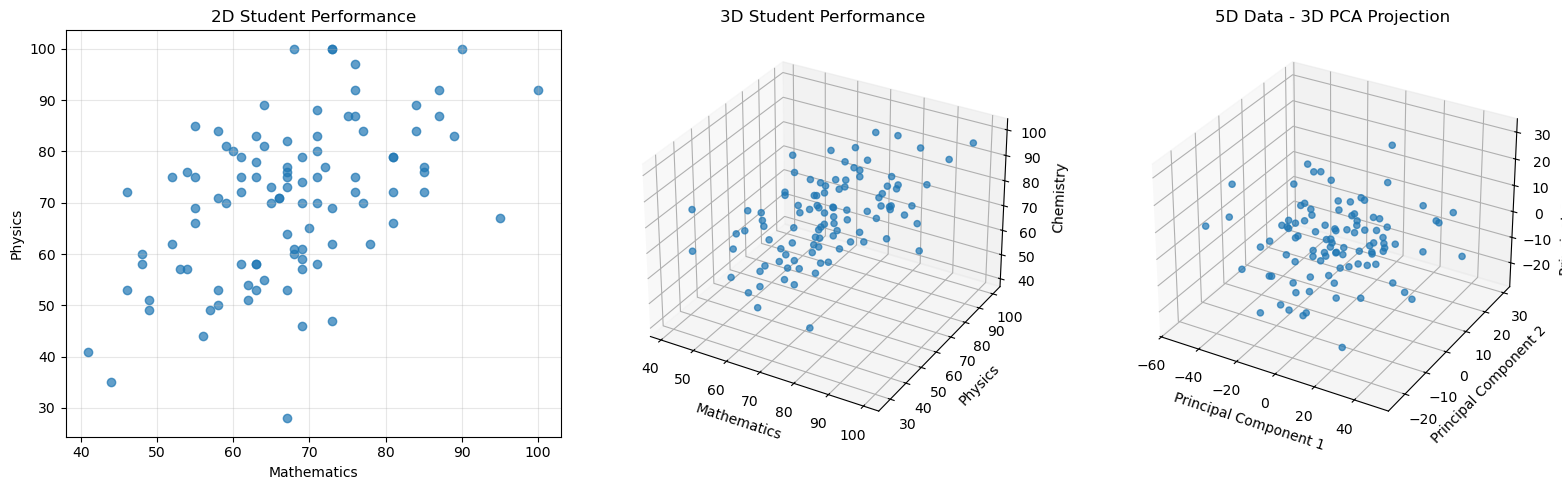

In [27]:
# Dimensionality Visualization

import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure(figsize=(16, 5))

# 2D Representation
ax1 = fig.add_subplot(131)

ax1.scatter(
    score_matrix[:, 0],
    score_matrix[:, 1],
    alpha=0.7
)

ax1.set_title("2D Student Performance")
ax1.set_xlabel("Mathematics")
ax1.set_ylabel("Physics")
ax1.grid(alpha=0.3)


# 3D Representation
ax2 = fig.add_subplot(132, projection='3d')

ax2.scatter(
    score_matrix[:, 0],
    score_matrix[:, 1],
    score_matrix[:, 2],
    alpha=0.7
)

ax2.set_title("3D Student Performance")
ax2.set_xlabel("Mathematics")
ax2.set_ylabel("Physics")
ax2.set_zlabel("Chemistry")


# 5D Representation using PCA
centered_data = score_matrix - np.mean(score_matrix, axis=0)

U, S, Vt = np.linalg.svd(
    centered_data,
    full_matrices=False
)

pca_data = centered_data @ Vt[:3].T

ax3 = fig.add_subplot(133, projection='3d')

ax3.scatter(
    pca_data[:, 0],
    pca_data[:, 1],
    pca_data[:, 2],
    alpha=0.7
)

ax3.set_title("5D Data - 3D PCA Projection")
ax3.set_xlabel("Principal Component 1")
ax3.set_ylabel("Principal Component 2")
ax3.set_zlabel("Principal Component 3")

plt.tight_layout()
plt.show()

In [28]:
# Hyperplane in Five-Dimensional Space

weights = np.array([1, 1, 1, 1, 1])

bias = -250

hyperplane_values = (
    np.dot(score_matrix, weights) + bias
)

print("Feature Dimensions:", score_matrix.shape[1])

print("Hyperplane Dimensions:",
      score_matrix.shape[1] - 1)

print("Hyperplane Equation:")
print("x1 + x2 + x3 + x4 + x5 - 250 = 0")

print("\nStudents above hyperplane:",
      np.sum(hyperplane_values > 0))

print("Students below hyperplane:",
      np.sum(hyperplane_values < 0))

print("Students on hyperplane:",
      np.sum(np.isclose(hyperplane_values, 0)))

Feature Dimensions: 5
Hyperplane Dimensions: 4
Hyperplane Equation:
x1 + x2 + x3 + x4 + x5 - 250 = 0

Students above hyperplane: 97
Students below hyperplane: 3
Students on hyperplane: 0


### Dimensionality and Hyperplane – Interpretation

The student performance dataset was explored in two-dimensional, three-dimensional and five-dimensional feature spaces.

In 2D, Mathematics and Physics were used as coordinate axes.

In 3D, Chemistry was added as the third coordinate.

The original dataset contains five subject features. PCA was used to represent the five-dimensional data in a three-dimensional visualization while retaining the distinction between original and reduced dimensions.

A hyperplane in five-dimensional space has four dimensions and can be represented using a linear equation.

The mathematical demonstration shows how hyperplanes can divide multidimensional data into different regions.

This concept is useful in machine learning classification and multidimensional data analysis.

# Part D – Eigenvalues & Decomposition

This section focuses on calculating the covariance matrix, eigenvalues and eigenvectors of student academic performance data.

Eigenvalue decomposition helps identify the principal directions of variation in multidimensional datasets.

In [29]:
# Import required library
import numpy as np

# Calculate Covariance Matrix
covariance_matrix = np.cov(score_matrix, rowvar=False)

print("Covariance Matrix:")
print(np.round(covariance_matrix, 2))

print("\nCovariance Matrix Shape:")
print(covariance_matrix.shape)

Covariance Matrix:
[[133.48  84.67  55.26  74.19  49.76]
 [ 84.67 219.39  86.09  62.35  75.96]
 [ 55.26  86.09 148.18  73.71  61.25]
 [ 74.19  62.35  73.71 201.67  45.33]
 [ 49.76  75.96  61.25  45.33 125.97]]

Covariance Matrix Shape:
(5, 5)


In [30]:
# Calculate Eigenvalues and Eigenvectors

eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)

# Sort in descending order
sorted_indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

print("Eigenvalues:")
print(np.round(eigenvalues, 4))

print("\nEigenvectors:")
print(np.round(eigenvectors, 4))

Eigenvalues:
[442.6857 150.671   92.0485  77.0732  66.2024]

Eigenvectors:
[[-0.399   0.051   0.4135  0.4975 -0.6478]
 [-0.565  -0.574   0.388  -0.3462  0.2846]
 [-0.4289  0.0045 -0.6469 -0.4196 -0.4706]
 [-0.4656  0.7938  0.1375 -0.1169  0.3472]
 [-0.3477 -0.1943 -0.491   0.6655  0.3966]]


In [31]:
# Calculate Explained Variance

total_variance = np.sum(eigenvalues)

explained_variance_ratio = eigenvalues / total_variance

explained_variance_percentage = explained_variance_ratio * 100

print("Explained Variance (%):")

for i, percentage in enumerate(explained_variance_percentage):
    print(f"Principal Component {i+1}: {percentage:.2f}%")

print("\nTotal Explained Variance:",
      round(np.sum(explained_variance_percentage), 2), "%")

Explained Variance (%):
Principal Component 1: 53.42%
Principal Component 2: 18.18%
Principal Component 3: 11.11%
Principal Component 4: 9.30%
Principal Component 5: 7.99%

Total Explained Variance: 100.0 %


### Eigenvalues and Eigenvectors – Interpretation

The covariance matrix was calculated using the academic performance scores of students across five subjects.

Eigenvalues and eigenvectors were obtained using the symmetric matrix eigenvalue decomposition method.

Eigenvalues represent the amount of variance associated with each principal direction, while eigenvectors represent the corresponding directions in the feature space.

The explained variance percentage helps identify how much of the total dataset variation is represented by each principal component.

These mathematical concepts form the foundation of Principal Component Analysis (PCA) and dimensionality reduction techniques used in Data Science and Machine Learning.

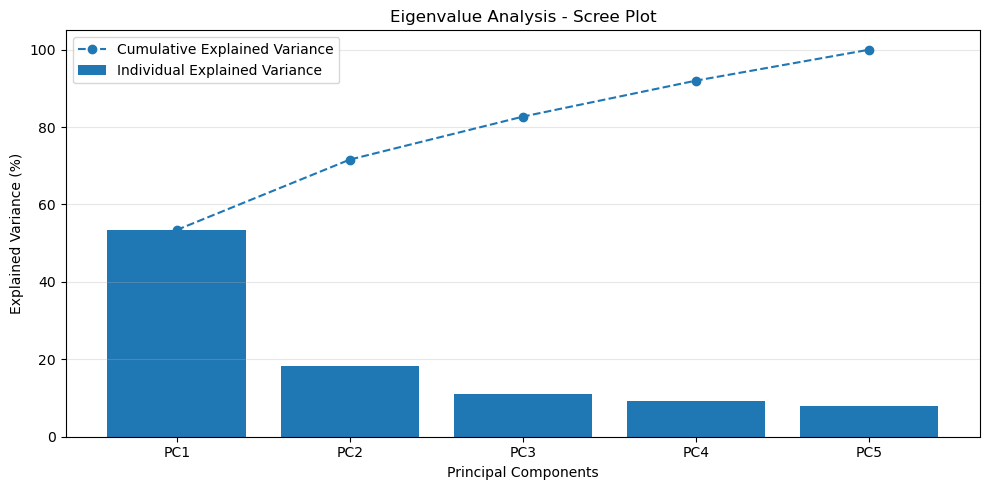

In [32]:
# Eigenvalue and Explained Variance Visualization

import matplotlib.pyplot as plt
import numpy as np

components = [
    f"PC{i+1}" for i in range(len(eigenvalues))
]

cumulative_variance = np.cumsum(
    explained_variance_percentage
)

plt.figure(figsize=(10, 5))

plt.bar(
    components,
    explained_variance_percentage,
    label="Individual Explained Variance"
)

plt.plot(
    components,
    cumulative_variance,
    marker="o",
    linestyle="--",
    label="Cumulative Explained Variance"
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("Eigenvalue Analysis - Scree Plot")

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# Verify Eigenvalue Decomposition

reconstructed_covariance = (
    eigenvectors
    @ np.diag(eigenvalues)
    @ eigenvectors.T
)

print("Original Covariance Matrix:")
print(np.round(covariance_matrix, 4))

print("\nReconstructed Covariance Matrix:")
print(np.round(reconstructed_covariance, 4))

if np.allclose(
    covariance_matrix,
    reconstructed_covariance
):
    print("\nEigenvalue Decomposition Verified Successfully!")
else:
    print("\nVerification Failed!")

Original Covariance Matrix:
[[133.4759  84.6738  55.2639  74.1947  49.7561]
 [ 84.6738 219.387   86.0902  62.3543  75.9581]
 [ 55.2639  86.0902 148.1797  73.7095  61.248 ]
 [ 74.1947  62.3543  73.7095 201.6711  45.3313]
 [ 49.7561  75.9581  61.248   45.3313 125.9672]]

Reconstructed Covariance Matrix:
[[133.4759  84.6738  55.2639  74.1947  49.7561]
 [ 84.6738 219.387   86.0902  62.3543  75.9581]
 [ 55.2639  86.0902 148.1797  73.7095  61.248 ]
 [ 74.1947  62.3543  73.7095 201.6711  45.3313]
 [ 49.7561  75.9581  61.248   45.3313 125.9672]]

Eigenvalue Decomposition Verified Successfully!


### Eigenvalue Visualization and Verification – Interpretation

A scree plot was generated to visualize the individual and cumulative explained variance of the principal components.

The eigenvalues indicate the amount of variance captured by each principal direction.

The cumulative explained variance helps identify how much total information is represented by the selected principal components.

The eigenvalue decomposition was also verified by reconstructing the original covariance matrix using eigenvectors and eigenvalues.

The reconstructed matrix closely matches the original covariance matrix, confirming the correctness of the decomposition.

# Project Conclusion – Calculative Foundation

This project successfully demonstrates the practical application of Linear Algebra concepts using Python and a synthetic Student Academic Performance Dataset.

The analysis covered four major areas:

**Part A – Vector & Matrix Fundamentals**

Student subject scores were represented as vectors. Norm-1, Norm-2, Dot Product, Angle Between Vectors, Cross Product and Vector Projection were calculated.

**Part B – Matrix Operations**

Matrix Addition, Matrix Multiplication, Transpose, Determinant and Inverse operations were performed on student performance data.

**Part C – Linear Transformations & Geometry**

The concepts of Lines, Planes and Hyperplanes were explored. Student data was represented in 2D, 3D and higher-dimensional spaces. PCA was used to visualize five-dimensional data in three dimensions.

**Part D – Eigenvalues & Decomposition**

The Covariance Matrix, Eigenvalues and Eigenvectors were calculated. Explained Variance and Eigenvalue Decomposition were analyzed and verified.

**Overall Conclusion**

This project strengthened the understanding of mathematical foundations used in Data Science, Artificial Intelligence and Machine Learning.

It demonstrated how Linear Algebra can transform multidimensional datasets into meaningful mathematical representations and analytical insights.